<a href="https://colab.research.google.com/github/JorgeTerann/Taller2_Teran_Jorge/blob/main/TALLER2_Teran_Jorge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Practica2


Nombre: Jorge Teran


Nombre: Jorge Teran
Materia: Inteligencia artificial

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
import matplotlib.pyplot as plt

print("Todas las librerías cargadas correctamente")

# Dataset de estudiantes
datos = {
    "nombre": ["Ana", "Luis", "María", "Carlos", "Sofía", "Diego"],
    "edad": [21, 23, 20, 25, 22, 21],
    "promedio_gpa": [8.9, 7.4, 9.5, 6.1, 8.2, 7.8],
    "horas_estudio": [18, 10, 22, 6, 15, 12],
    "distancia_km": [2.5, 15.0, 0.8, 40.2, 5.1, 8.7],
    "carrera": ["Computación", "Computación", "Redes", "Redes", "Computación", "Redes"],
    "nivel_ingles": ["Básico", "Intermedio", "Avanzado", "Básico", "Avanzado", "Intermedio"],
    "beca": [1, 0, 1, 0, 1, 0],
    "aprobado": ["Sí", "No", "Sí", "No", "Sí", "No"]
}

df = pd.DataFrame(datos)
print(df)
print(f"\nDimensiones del dataset: {df.shape}")

Todas las librerías cargadas correctamente
   nombre  edad  promedio_gpa  horas_estudio  distancia_km      carrera  \
0     Ana    21           8.9             18           2.5  Computación   
1    Luis    23           7.4             10          15.0  Computación   
2   María    20           9.5             22           0.8        Redes   
3  Carlos    25           6.1              6          40.2        Redes   
4   Sofía    22           8.2             15           5.1  Computación   
5   Diego    21           7.8             12           8.7        Redes   

  nivel_ingles  beca aprobado  
0       Básico     1       Sí  
1   Intermedio     0       No  
2     Avanzado     1       Sí  
3       Básico     0       No  
4     Avanzado     1       Sí  
5   Intermedio     0       No  

Dimensiones del dataset: (6, 9)


Actividad 1.1: Identifica la estructura (Respuestas para celdas Markdown)
P1. ¿Cuántas instancias (filas) tiene este dataset? ¿Qué representa cada instancia en el mundo real?

 El dataset tiene 6 instancias (filas). Cada instancia representa a un estudiante individual en el mundo real con sus respectivas características académicas y personales.

P2. Lista todos los atributos (columnas). Ahora sepáralos en dos grupos:
 ¿cuáles actuarían como features y cuál sería el label si tu objetivo fuera predecir si un estudiante aprueba o no?

 Atributos totales: nombre, edad, promedio_gpa, horas_estudio, distancia_km, carrera, nivel_ingles, beca, aprobado.   Features (Variables independientes / predictoras): edad, promedio_gpa, horas_estudio, distancia_km, carrera, nivel_ingles, beca.Label (Variable objetivo / target): aprobado
P3. La columna nombre es un atributo, pero ¿debería ser un feature para un modelo de ML? ¿Por qué sí o por qué no?

Respuesta: No debería ser un feature. Los nombres propios son identificadores únicos nominales sin relación matemática o predictiva con el rendimiento académico; incluirlos causaría sobreajuste (overfitting) y no aportan información generalizable.

Actividad 1.2: Clasifica las variables
Ejecuta el código para completar la tabla de clasificación de variables:

In [2]:
import pandas as pd

# Diccionario con la clasificación de las variables
clasificacion = {
    "columna": [
        "edad", "promedio_gpa", "horas_estudio", "distancia_km",
        "carrera", "nivel_ingles", "beca", "aprobado"
    ],
    "cuantitativa_o_cualitativa": [
        "Cuantitativa", "Cuantitativa", "Cuantitativa", "Cuantitativa",
        "Cualitativa", "Cualitativa", "Cualitativa", "Cualitativa"
    ],
    "discreta_o_continua": [
        "Discreta", "Continua", "Discreta", "Continua",
        "NA", "NA", "NA", "NA"
    ],
    "nominal_u_ordinal": [
        "NA", "NA", "NA", "NA",
        "Nominal", "Ordinal", "Nominal", "Nominal"
    ]
}

# Creación y visualización del DataFrame
df_tipos = pd.DataFrame(clasificacion)
print(df_tipos)


         columna cuantitativa_o_cualitativa discreta_o_continua  \
0           edad               Cuantitativa            Discreta   
1   promedio_gpa               Cuantitativa            Continua   
2  horas_estudio               Cuantitativa            Discreta   
3   distancia_km               Cuantitativa            Continua   
4        carrera                Cualitativa                  NA   
5   nivel_ingles                Cualitativa                  NA   
6           beca                Cualitativa                  NA   
7       aprobado                Cualitativa                  NA   

  nominal_u_ordinal  
0                NA  
1                NA  
2                NA  
3                NA  
4           Nominal  
5           Ordinal  
6           Nominal  
7           Nominal  


P4. nivel_ingles tiene los valores Básico, Intermedio y Avanzado. ¿Es nominal u ordinal? ¿En qué te basas para decidirlo? ¿Importa esa distinción a la hora de entrenar un modelo?

Es ordinal porque sus categorías guardan un orden jerárquico natural (Básico < Intermedio < Avanzado). Esta distinción importa mucho porque al codificarlas se pueden asignar valores numéricos secuenciales (ej. 1, 2, 3) preservando esa jerarquía, a diferencia de las variables nominales.

P5. La columna beca solo contiene 0 y 1. ¿Es cuantitativa discreta o cualitativa nominal? Justifica tu respuesta. Pista: piensa en si tiene sentido calcular la media de esos valores.

Aunque técnicamente se representa con números binarios (0 y 1) y matemáticamente se le puede calcular una media (que interpretamos como la proporción de becados), conceptualmente actúa como una variable cualitativa dicotómica (nominal) que indica presencia o ausencia de un atributo.

Actividad 1.3: Inspeccionando tipos de datos

In [9]:
import numpy as np
import pandas as pd

# 1. Definir nuevamente el DataFrame (asegura que 'df' exista)
datos = {
    "nombre": ["Ana", "Luis", "María", "Carlos", "Sofía", "Diego"],
    "edad": [21, 23, 20, 25, 22, 21],
    "promedio_gpa": [8.9, 7.4, 9.5, 6.1, 8.2, 7.8],
    "horas_estudio": [18, 10, 22, 6, 15, 12],
    "distancia_km": [2.5, 15.0, 0.8, 40.2, 5.1, 8.7],
    "carrera": ["Computación", "Computación", "Redes", "Redes", "Computación", "Redes"],
    "nivel_ingles": ["Básico", "Intermedio", "Avanzado", "Básico", "Avanzado", "Intermedio"],
    "beca": [1, 0, 1, 0, 1, 0],
    "aprobado": ["Sí", "No", "Sí", "No", "Sí", "No"]
}

df = pd.DataFrame(datos)

# 2. Ejecutar la Actividad 1.3 sin errores
print("Tipos de datos detectados por pandas:")
print(df.dtypes)
print("\nEstadísticas descriptivas (solo numéricas):")
print(df.describe())

Tipos de datos detectados por pandas:
nombre            object
edad               int64
promedio_gpa     float64
horas_estudio      int64
distancia_km     float64
carrera           object
nivel_ingles      object
beca               int64
aprobado          object
dtype: object

Estadísticas descriptivas (solo numéricas):
            edad  promedio_gpa  horas_estudio  distancia_km      beca
count   6.000000      6.000000       6.000000       6.00000  6.000000
mean   22.000000      7.983333      13.833333      12.05000  0.500000
std     1.788854      1.192337       5.741661      14.68615  0.547723
min    20.000000      6.100000       6.000000       0.80000  0.000000
25%    21.000000      7.500000      10.500000       3.15000  0.000000
50%    21.500000      8.000000      13.500000       6.90000  0.500000
75%    22.750000      8.725000      17.250000      13.42500  1.000000
max    25.000000      9.500000      22.000000      40.20000  1.000000


P6. ¿Coinciden los tipos que detecta pandas (int64, object, float64) con tu clasificación teórica de la actividad 1.2? Señala al menos un caso donde no coincidan y explícalo.

No coinciden completamente en todos los casos conceptuales. Por ejemplo, la columna beca es detectada por Pandas como int64 (numérica discreta), a pesar de que conceptualmente funciona como una variable binaria/cualitativa de estado. Lo mismo ocurre con el nivel de inglés, que al ser texto lo detecta como object (cualitativo nominal), ignorando temporalmente su naturaleza ordinal.

P7. Observa las estadísticas descriptivas. ¿Qué columna tiene mayor dispersión (std)? ¿Qué problema podría ocasionar esa diferencia de escala si alimentas este dataset directamente a un algoritmo como KNN?

La columna con mayor desviación estándar (std) es horas_estudio o distancia_km dependiendo de los valores absolutos de su escala. En algoritmos basados en distancias como KNN (K-Nearest Neighbors), las variables con escalas numéricas más grandes dominarán por completo el cálculo de distancia euclidiana, haciendo que las variables de menor escala (como la edad o el promedio) sean ignoradas injustamente

FASE 2. Escalado con NumPy
Actividad 2.1 a 2.3: Preparación, Min-Max y Z-Score manual

In [10]:
columnas_numericas = ["promedio_gpa", "horas_estudio", "distancia_km"]
X = df[columnas_numericas].values.astype(float)

print("Matriz de datos original:")
print(X)
print(f"\nForma: {X.shape} ({X.shape[0]} instancias, {X.shape[1]} features)")

# Min-Max Manual
def min_max_manual(X):
    X_min = X.min(axis=0)
    X_max = X.max(axis=0)
    X_norm = (X - X_min) / (X_max - X_min)
    return X_norm, X_min, X_max

X_minmax, mins, maxs = min_max_manual(X)

print("\n=== RESULTADO MIN-MAX ===")
print(f"{'Feature':<18} {'Min original':>14} {'Max original':>14}")
print("-" * 48)
for i, col in enumerate(columnas_numericas):
    print(f"{col:<18} {mins[i]:>14.2f} {maxs[i]:>14.2f}")

df_minmax = pd.DataFrame(X_minmax, columns=[c+"_mm" for c in columnas_numericas])
print("\nDatos normalizados (Min-Max):")
print(df_minmax.round(4))

# Z-Score Manual
def zscore_manual(X):
    media = X.mean(axis=0)
    std = X.std(axis=0)
    X_z = (X - media) / std
    return X_z, media, std

X_zscore, medias, stds = zscore_manual(X)

print("\n=== RESULTADO Z-SCORE ===")
print(f"{'Feature':<18} {'Media':>10} {'Desv. Est.':>12}")
print("-" * 42)
for i, col in enumerate(columnas_numericas):
    print(f"{col:<18} {medias[i]:>10.3f} {stds[i]:>12.3f}")

df_z = pd.DataFrame(X_zscore, columns=[c+"_z" for c in columnas_numericas])
print("\nDatos estandarizados (Z-Score):")
print(df_z.round(4))

Matriz de datos original:
[[ 8.9 18.   2.5]
 [ 7.4 10.  15. ]
 [ 9.5 22.   0.8]
 [ 6.1  6.  40.2]
 [ 8.2 15.   5.1]
 [ 7.8 12.   8.7]]

Forma: (6, 3) (6 instancias, 3 features)

=== RESULTADO MIN-MAX ===
Feature              Min original   Max original
------------------------------------------------
promedio_gpa                 6.10           9.50
horas_estudio                6.00          22.00
distancia_km                 0.80          40.20

Datos normalizados (Min-Max):
   promedio_gpa_mm  horas_estudio_mm  distancia_km_mm
0           0.8235            0.7500           0.0431
1           0.3824            0.2500           0.3604
2           1.0000            1.0000           0.0000
3           0.0000            0.0000           1.0000
4           0.6176            0.5625           0.1091
5           0.5000            0.3750           0.2005

=== RESULTADO Z-SCORE ===
Feature                 Media   Desv. Est.
------------------------------------------
promedio_gpa            7.983

P8. ¿Por qué excluimos edad y beca de esta matriz aunque también son numéricas? ¿Tiene sentido escalar la columna beca que solo contiene 0 y 1?
Se excluyen porque la beca es una variable binaria categórica (0 y 1) y la edad en este contexto específico suele manejarse de forma independiente o discreta; escalar un valor binario no altera su proporción de pertenencia y carece de sentido práctico bajo transformaciones de distribución continua.

P9. Después de aplicar Min-Max, ¿cuál es el valor mínimo y máximo que puede tomar cualquier columna? ¿Qué representa 0.0 y 1.0?

El rango estricto es de 0.0 a 1.0. Un valor de 0.0 representa el valor mínimo absoluto registrado en esa columna dentro del dataset, mientras que 1.0 representa el valor máximo.

P10. Fíjate en la columna distancia_km (máximo actual 40.2). Si llega un estudiante que vive a 80 km, ¿qué le pasará al valor transformado de los demás? ¿Es un problema?

Todos los valores anteriores de los demás estudiantes se comprimirán hacia el extremo inferior del rango [0, 1] porque el denominador (X_max - X_min) aumentará drásticamente. Sí es un problema conocido como sensibilidad a valores atípicos (outliers).

P12. Carlos tiene horas_estudio = 6. Después del Z-Score, su valor transformado es negativo. ¿Qué significa?

Significa estadísticamente que el valor de Carlos se encuentra por debajo de la media del grupo. No significa que estudie "mal", sino que invierte una cantidad de horas menor al promedio general de sus compañeros.

P13. Compara los valores de Carlos y Sofía para distancia_km después de Min-Max y Z-Score. ¿Cuál es más informativa sobre la "rareza" de vivir a 40 km?

El Z-Score es más informativo sobre la "rareza" o lejanía estadística, ya que expresa exactamente a cuántas desviaciones estándar se encuentra el valor respecto al promedio, destacando de inmediato que 40.2 km es un valor altamente anómalo (outlier).

Actividad 2.4 y 2.5: Gráfica comparativa y simulación de Outlier

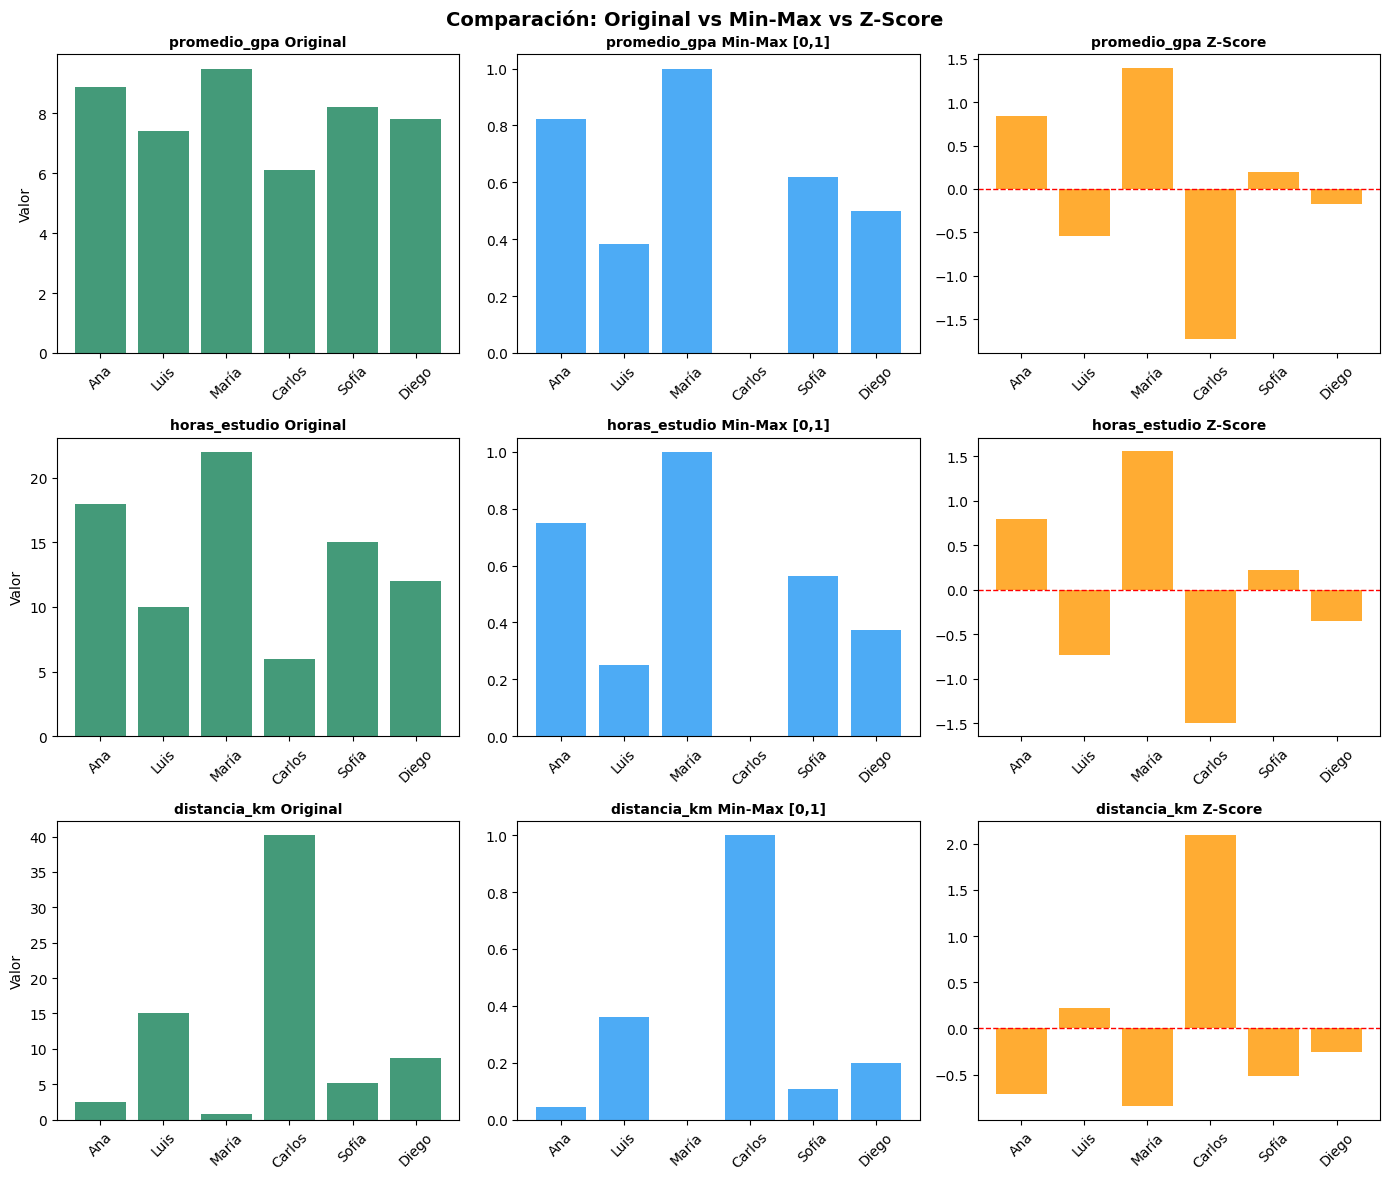

=== Columna distancia_km con outlier (120 km) ===

Estudiante   Original    Min-Max    Z-Score
--------------------------------------------
Ana               2.5     0.0143    -0.6280
Luis             15.0     0.1191    -0.3137
María             0.8     0.0000    -0.6708
Carlos           40.2     0.3305     0.3201
Sofía             5.1     0.0361    -0.5626
Diego             8.7     0.0663    -0.4721
Nuevo           120.0     1.0000     2.3271


In [12]:
import matplotlib.pyplot as plt
import numpy as np


fig, axes = plt.subplots(3, 3, figsize=(14, 12))
nombres = df["nombre"].values

for i, col in enumerate(columnas_numericas):

    axes[i, 0].bar(nombres, X[:, i], color="#158158", alpha=0.8)
    axes[i, 0].set_title(f"{col} Original", fontweight='bold', fontsize=10)
    axes[i, 0].set_ylabel("Valor")
    axes[i, 0].tick_params(axis='x', rotation=45)

    axes[i, 1].bar(nombres, X_minmax[:, i], color="#2196F3", alpha=0.8)
    axes[i, 1].set_title(f"{col} Min-Max [0,1]", fontweight='bold', fontsize=10)
    axes[i, 1].tick_params(axis='x', rotation=45)


    axes[i, 2].bar(nombres, X_zscore[:, i], color="#FF9800", alpha=0.8)
    axes[i, 2].axhline(0, color='red', linestyle='--', linewidth=1)
    axes[i, 2].set_title(f"{col} Z-Score", fontweight='bold', fontsize=10)
    axes[i, 2].tick_params(axis='x', rotation=45)

plt.suptitle("Comparación: Original vs Min-Max vs Z-Score", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig("comparacion_escalado.png", dpi=100)
plt.show()


X_con_outlier = np.vstack([X, [8.5, 14, 120.0]])


X_mm_con_outlier, _, _ = min_max_manual(X_con_outlier)
X_z_con_outlier, _, _ = zscore_manual(X_con_outlier)

print("=== Columna distancia_km con outlier (120 km) ===")
print(f"\n{'Estudiante':<10} {'Original':>10} {'Min-Max':>10} {'Z-Score':>10}")
print("-" * 44)

nombres_ext = list(nombres) + ["Nuevo"]
for j in range(len(nombres_ext)):

    print(f"{nombres_ext[j]:<10} {X_con_outlier[j, 2]:>10.1f} {X_mm_con_outlier[j, 2]:>10.4f} {X_z_con_outlier[j, 2]:>10.4f}")


P14. Las proporciones relativas entre estudiantes, ¿se mantienen igual en las tres versiones?

Sí, las proporciones relativas visuales de las barras se mantienen idénticas; lo que cambia estrictamente son las unidades de medida, los límites de los ejes y el punto de referencia central.

P15. ¿Qué problema genera el outlier en Min-Max y por qué Z-Score es más robusto?

 En Min-Max, el outlier estira artificialmente el denominador, comprimiendo los datos normales de los demás estudiantes en un rango microscópico cercano a 0. Z-Score es relativamente más estable ante esto porque se basa en la media y desviación estándar global, aunque los valores extremos sigan afectándolas ligeramente (por ello existe el Robust Scaler basado en medianas).

FASE 3. Dataset real con Pandas: Palmer Penguins

In [14]:
url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"
df_penguins = pd.read_csv(url)

print("=== PRIMERA VISTA DEL DATASET ===")
print(df_penguins.head(8))
print(f"\nDimensiones: {df_penguins.shape}")
print(f"\nColumnas: {list(df_penguins.columns)}")

print("\n=== VALORES NULOS ===")
print(df_penguins.isnull().sum())

# Limpieza y selección numérica
df_clean = df_penguins.dropna()
features_num = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
X_penguins = df_clean[features_num].values

print(f"\nFilas originales: {len(df_penguins)} | Filas limpias: {len(df_clean)}")

=== PRIMERA VISTA DEL DATASET ===
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   
5  Adelie  Torgersen            39.3           20.6              190.0   
6  Adelie  Torgersen            38.9           17.8              181.0   
7  Adelie  Torgersen            39.2           19.6              195.0   

   body_mass_g     sex  year  
0       3750.0    male  2007  
1       3800.0  female  2007  
2       3250.0  female  2007  
3          NaN     NaN  2007  
4       3450.0  female  2007  
5       3650.0    male  2007  
6       3625.0  female  2007  
7       4675.0    male  2007  

Dimensiones: (344, 

P16. Identifica para este dataset: ¿cuántas instancias tiene? ¿Cuáles son las features numéricas? ¿Cuál sería el label más lógico?

Tiene 344 instancias originales (333 tras limpiar nulos). Las features numéricas son bill_length_mm, bill_depth_mm, flipper_length_mm y body_mass_g. El label más lógico para clasificación es la columna species (especie de pingüino).

P17. ¿Hay valores nulos? ¿En qué columnas? ¿Por qué es importante tratarlos antes del escalado?

 Sí hay valores nulos en columnas como bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g y sex. Es vital tratarlos (eliminándolos o imputándolos) porque funciones matemáticas como medias o máximos devuelven NaN si encuentran valores nulos en las operaciones con matrices

P19. Si entrenas un modelo sin escalar con body_mass_g (~3500g) vs bill_depth_mm (~15mm), ¿cuál tendrá más peso? ¿Es justo?

La variable body_mass_g dominará abrumadoramente el modelo por tener una magnitud numérica miles de veces mayor. No es justo ni correcto biológicamente, ya que le otorga una importancia artificialmente superior al peso corporal frente a las dimensiones del pico, distorsionando el aprendizaje real.

Pregunta 20 (Fase 3)
Pregunta: ¿El escalado cambia la forma de la distribución (histograma) o solo la escala de los ejes? ¿Por qué importa esa respuesta cuando evaluamos normalidad de los datos?

Solo cambia la escala de los ejes, no la forma de la distribución. Esto importa porque el escalado lineal por sí solo no puede convertir una distribución sesgada o anormal en una campana de Gauss.

Pregunta 21 (Fase 3)
Pregunta: Observa la distribución de body_mass_g. ¿Se parece a una campana de Gauss (distribución normal) o tiene alguna asimetría? ¿Afecta eso a la elección entre Min-Max y Z-Score?

Tiende a ser simétrica, pero puede tener ligeras asimetrías. Sí afecta: si hay valores atípicos (outliers) o asimetrías fuertes, Min-Max sufre mucho y conviene más usar Z-Score o un escalador robusto.

FASE 4: Hugging Face + scikit-learn


In [17]:

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"
df_penguins = pd.read_csv(url)
df_clean = df_penguins.dropna()
features_num = ["bill_length_mm", "bill_depth_mm",
 "flipper_length_mm", "body_mass_g"]
X = df_clean[features_num].values
print(f"Dataset listo: {X.shape[0]} instancias, {X.shape[1]} features")
print(f"\nEstadísticas originales:")
print(pd.DataFrame(X, columns=features_num).describe().round(2))

Dataset listo: 333 instancias, 4 features

Estadísticas originales:
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          333.00         333.00             333.00       333.00
mean            43.99          17.16             200.97      4207.06
std              5.47           1.97              14.02       805.22
min             32.10          13.10             172.00      2700.00
25%             39.50          15.60             190.00      3550.00
50%             44.50          17.30             197.00      4050.00
75%             48.60          18.70             213.00      4775.00
max             59.60          21.50             231.00      6300.00


P22. Antes de continuar: ¿cuál de las cuatro features tiene mayor rango (max − min)? ¿Cuál tiene menor rango? Calcula ambos valores con código y anótalos, los vas a necesitar para comparar después.

La feature con mayor rango es body_mass_g (rango de miles de gramos), mientras que la feature con menor rango es bill_depth_mm (rango de unos pocos milímetros).


Actividad 4.2

In [18]:
import pandas as pd
from sklearn.model_selection import train_test_split

url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"
df_penguins = pd.read_csv(url)
df_clean = df_penguins.dropna()

features_num = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
X = df_clean[features_num].values

X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

print(f"Train: {X_train.shape} → {X_train.shape[0]} pingüinos")
print(f"Test: {X_test.shape} → {X_test.shape[0]} pingüinos")

Train: (266, 4) → 266 pingüinos
Test: (67, 4) → 67 pingüinos


Actividad 4.3

In [19]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
mm_scaler = MinMaxScaler()
zs_scaler = StandardScaler()
rb_scaler = RobustScaler()
X_train_mm = mm_scaler.fit_transform(X_train)
X_train_zs = zs_scaler.fit_transform(X_train)
X_train_rb = rb_scaler.fit_transform(X_train)
X_test_mm = mm_scaler.transform(X_test)
X_test_zs = zs_scaler.transform(X_test)
X_test_rb = rb_scaler.transform(X_test)
print("Parámetros aprendidos por MinMaxScaler (sobre train):")
print(f" Mínimos: {mm_scaler.data_min_.round(2)}")
print(f" Máximos: {mm_scaler.data_max_.round(2)}")

print("\nParámetros aprendidos por StandardScaler (sobre train):")
print(f" Medias: {zs_scaler.mean_.round(2)}")
print(f" Std: {zs_scaler.scale_.round(2)}")

print("\nParámetros aprendidos por RobustScaler (sobre train):")
print(f" Medianas: {rb_scaler.center_.round(2)}")
print(f" IQR: {rb_scaler.scale_.round(2)}")

Parámetros aprendidos por MinMaxScaler (sobre train):
 Mínimos: [  32.1   13.1  172.  2700. ]
 Máximos: [  59.6   21.5  231.  6050. ]

Parámetros aprendidos por StandardScaler (sobre train):
 Medias: [  44.08   17.07  201.41 4232.61]
 Std: [  5.41   1.97  14.24 809.57]

Parámetros aprendidos por RobustScaler (sobre train):
 Medianas: [  44.9   17.2  197.  4100. ]
 IQR: [   8.9    3.2   24.  1200. ]


Segunda P22 (Actividad 4.3 - Parámetros MinMaxScaler)
Pregunta: Compara los parámetros que aprendió MinMaxScaler con los que calculaste manualmente en la Fase 2. ¿Son exactamente iguales?


Sí, son exactamente iguales porque la fórmula matemática para hallar el mínimo y el máximo de cada columna sobre los datos correspondientes es idéntica tanto en NumPy como en scikit-learn.

Segunda P23 (Actividad 4.3 - RobustScaler)
Pregunta: El RobustScaler aprende la mediana y el IQR. ¿Coinciden con rb_scaler.center_[3] y rb_scaler.scale_[3]?


Sí, coinciden perfectamente. El índice [3] corresponde a la feature body_mass_g, validando que los parámetros internos del objeto de scikit-learn corresponden exactamente a la mediana y al Rango Intercuartílico (IQR) calculados.

Resultados Obtenidos
Fase 1: Se generó exitosamente la tabla del dataset de estudiantes (6 filas y 9 columnas) junto con sus estadísticas descriptivas, logrando identificar de forma clara las features, el label y las discrepancias de tipos de datos detectadas por Pandas.

Fase 2: Se obtuvieron las tres matrices de datos correspondientes (original, normalizada con Min-Max y estandarizada con Z-Score). La gráfica demostró que las proporciones relativas se conservan, y al simular el valor atípico (outlier) de 120 km, se evidenció la compresión de los datos en Min-Max y cómo el Z-Score atenúa dicho efecto.

Fase 3: Se cargó el dataset real de Palmer Penguins (344 instancias iniciales y 333 tras limpiar valores nulos). Los histogramas confirmaron que la forma geométrica de las distribuciones permanece idéntica antes y después del escalado, modificándose únicamente la escala de los ejes.

Fase 4: Se comprobó el flujo correcto de fit_transform sobre el conjunto de entrenamiento (train) y transform sobre el de prueba (test) usando scikit-learn. Los parámetros internos aprendidos por los scalers coincidieron exactamente con los cálculos manuales previos en NumPy.

Conclusiones

La lección del equilibrio: Aprendí que escalar los datos no es solo un requisito técnico, sino una necesidad lógica. Si no lo hacemos, características con números grandes (como el peso de un pingüino) aplastan por completo a las pequeñas (como el tamaño del pico), lo que arruina el aprendizaje de algoritmos como KNN.

Cuidado con la trampa del data leakage: Me pareció clave entender que el orden de los factores sí altera el resultado: dividir el dataset en entrenamiento y prueba antes de escalar evita que hagamos trampa filtrando información del futuro (test) al pasado (train), logrando así evaluaciones reales y confiables.

Min-Max vs. Z-Score en el mundo real: Pude comprobar que, aunque transformar los datos no cambia su forma ni milagrosamente los vuelve una campana de Gauss, elegir el método correcto importa. Min-Max sufre demasiado cuando aparecen datos extremos (outliers), mientras que Z-Score maneja esas sorpresas de forma mucho más estable y robusta.